# 03 - Model Experiments & Baseline CNN Training | VNDCash
**Dự án**: XÂY DỰNG ỨNG DỤNG NHẬN DIỆN TIỀN GIẤY VIỆT NAM BẰNG CNN  
**Stack**: Stack02 - Custom CNN & Training Engine  
**Thành viên phụ trách**: Tô Quang Dũng, Lê Quang Minh Nhật, Nguyễn Trường Tấn  

Notebook này thực hiện thử nghiệm huấn luyện mô hình **Baseline CNN** tự thiết kế trên bộ dữ liệu VNDCash (09 mệnh giá), trực quan hóa kiến trúc mô hình, kiểm tra DataLoader, phân tích các đường cong học tập (**Learning Curves**), và đánh giá dự đoán trực quan trên tập Validation.

In [1]:
import sys
from pathlib import Path
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Thiết lập Project Root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.config import load_config
from src.utils.seed import seed_everything
from src.models.factory import build_model, count_parameters, get_model_summary
from src.data.dataset import get_dataloaders
from src.data.preprocessing import denormalize_tensor
from src.training.losses import compute_class_weights

seed_everything(42)
print('PyTorch Version:', torch.__version__)
print('CUDA Available :', torch.cuda.is_available())
print('Project Root   :', PROJECT_ROOT)

PyTorch Version: 2.14.1+cpu
CUDA Available : False
Project Root   : C:\Users\ndt06\Desktop\VNDCash


## 1. Khởi tạo và Phân tích Kiến trúc Baseline CNN
Kiểm tra xem mô hình có đảm bảo đúng **9 đầu ra** (tương ứng 9 mệnh giá) và số lượng tham số gọn nhẹ (~1.44M params) phù hợp triển khai di động.

In [2]:
model = build_model('baseline_cnn', num_classes=9, in_channels=3, dropout=0.3)
summary = get_model_summary(model, input_size=(1, 3, 224, 224))

print('=' * 60)
print('           THÔNG TIN KIẾN TRÚC BASELINE CNN')
print('=' * 60)
print(f"Input Shape      : {summary['input_shape']}")
print(f"Output Shape     : {summary['output_shape']} (Đúng 9 đầu ra)")
print(f"Số lượng Lớp     : {summary['num_classes']} mệnh giá")
print(f"Tổng số tham số  : {summary['total_params']:,} tham số")
print(f"Kích thước model : {summary['total_params'] * 4 / (1024 * 1024):.2f} MB")
print('=' * 60)
print('\nChi tiết các khối tầng của mô hình:')
print(model)

           THÔNG TIN KIẾN TRÚC BASELINE CNN
Input Shape      : [1, 3, 224, 224]
Output Shape     : [1, 9] (Đúng 9 đầu ra)
Số lượng Lớp     : 9 mệnh giá
Tổng số tham số  : 1,440,297 tham số
Kích thước model : 5.49 MB

Chi tiết các khối tầng của mô hình:
BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(12

## 2. Kiểm tra DataLoaders và Trọng số Lớp (Class Weights)
Nạp DataLoader từ `configs/data.yaml` và kiểm tra trọng số phạt nghịch đảo tần suất cho 3 lớp thiếu mẫu (5k, 20k, 50k).

In [3]:
data_cfg_path = PROJECT_ROOT / 'configs' / 'data.yaml'
splits_csv_path = PROJECT_ROOT / 'data' / 'metadata' / 'splits.csv'

train_loader, val_loader, test_loader = get_dataloaders(
    config_path=data_cfg_path,
    splits_csv_path=splits_csv_path,
    batch_size=32,
    num_workers=0
)

print(f"Số batch Train : {len(train_loader)} (mỗi batch 32 ảnh)")
print(f"Số batch Val   : {len(val_loader)}")
print(f"Số batch Test  : {len(test_loader)}")

# Trọng số lớp
class_weights = compute_class_weights(splits_csv_path, num_classes=9)
classes = ['1k', '2k', '5k', '10k', '20k', '50k', '100k', '200k', '500k']
for c, w in zip(classes, class_weights.tolist()):
    print(f"  - Mệnh giá {c:>5}: trọng số loss = {w:.3f}")

Số batch Train : 43 (mỗi batch 32 ảnh)
Số batch Val   : 10
Số batch Test  : 10
  - Mệnh giá    1k: trọng số loss = 0.859
  - Mệnh giá    2k: trọng số loss = 0.859
  - Mệnh giá    5k: trọng số loss = 1.281
  - Mệnh giá   10k: trọng số loss = 0.859
  - Mệnh giá   20k: trọng số loss = 1.281
  - Mệnh giá   50k: trọng số loss = 1.281
  - Mệnh giá  100k: trọng số loss = 0.859
  - Mệnh giá  200k: trọng số loss = 0.859
  - Mệnh giá  500k: trọng số loss = 0.859


## 3. Trực quan hóa Đường cong học tập (Learning Curves)
Nạp kết quả huấn luyện từ `artifacts/logs/baseline_cnn_experiment_history.csv` và vẽ đồ thị Train vs Validation Loss & Accuracy.

Bảng lịch sử huấn luyện:


,epoch,train_loss,train_acc,val_loss,val_acc,lr
0,1,1.69424,0.44126,1.45547,0.48000,0.001
1,2,1.07170,0.68429,1.12790,0.64667,0.001
2,3,0.87435,0.76799,0.92317,0.75333,0.001


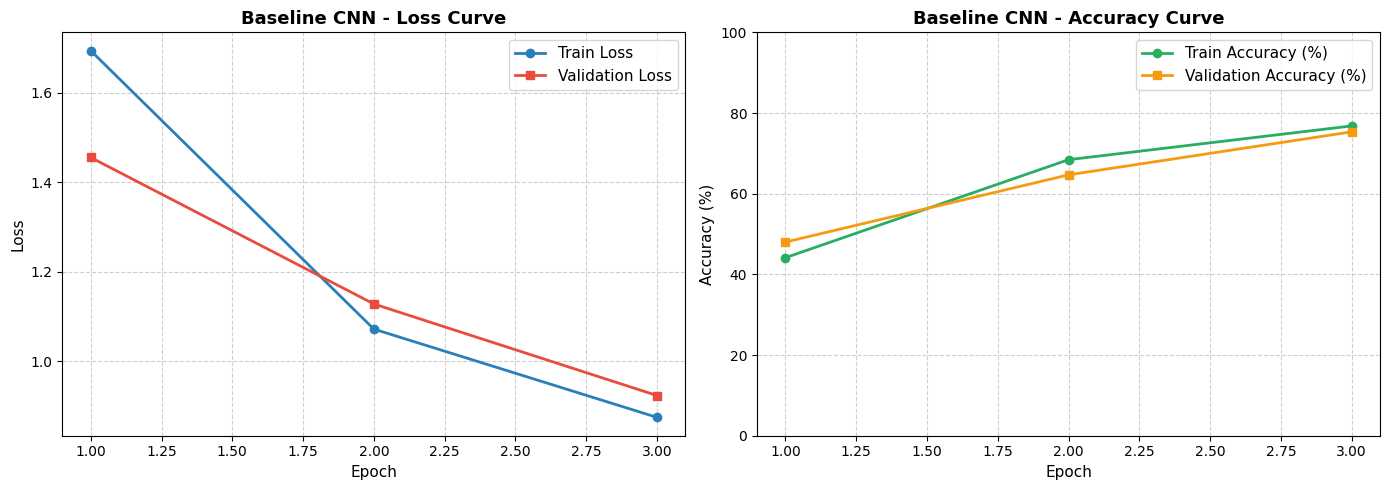

In [4]:
history_csv = PROJECT_ROOT / 'artifacts' / 'logs' / 'baseline_cnn_experiment_history.csv'
if history_csv.exists():
    df_hist = pd.read_csv(history_csv)
    print('Bảng lịch sử huấn luyện:')
    display(df_hist)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Loss Curve
    ax1.plot(df_hist['epoch'], df_hist['train_loss'], 'o-', label='Train Loss', color='#2980b9', lw=2)
    ax1.plot(df_hist['epoch'], df_hist['val_loss'], 's-', label='Validation Loss', color='#e74c3c', lw=2)
    ax1.set_title('Baseline CNN - Loss Curve', fontsize=13, fontweight='bold')
    ax1.set_xlabel('Epoch', fontsize=11)
    ax1.set_ylabel('Loss', fontsize=11)
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.legend(fontsize=11)

    # Accuracy Curve
    ax2.plot(df_hist['epoch'], df_hist['train_acc'] * 100, 'o-', label='Train Accuracy (%)', color='#27ae60', lw=2)
    ax2.plot(df_hist['epoch'], df_hist['val_acc'] * 100, 's-', label='Validation Accuracy (%)', color='#f39c12', lw=2)
    ax2.set_title('Baseline CNN - Accuracy Curve', fontsize=13, fontweight='bold')
    ax2.set_xlabel('Epoch', fontsize=11)
    ax2.set_ylabel('Accuracy (%)', fontsize=11)
    ax2.set_ylim(0, 100)
    ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.legend(fontsize=11)

    plt.tight_layout()
    plt.show()
else:
    print('Chưa tìm thấy file history. Vui lòng chạy python scripts/train.py trước!')

## 4. Nạp Best Checkpoint và Đánh giá Mẫu Dự đoán (Inference Demo)
Nạp trọng số tối ưu từ `artifacts/checkpoints/baseline_cnn_best.pt` và kiểm thử dự đoán trên 6 ảnh từ tập Validation kèm độ tự tin (Confidence %). 

Đã nạp checkpoint tốt nhất tại epoch 3 với metrics:
  - train_loss: 0.8743504231546769
  - train_acc: 0.7679882525697503
  - val_loss: 0.9231732749938965
  - val_acc: 0.7533333333333333
  - lr: 0.001


C:\Users\ndt06\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


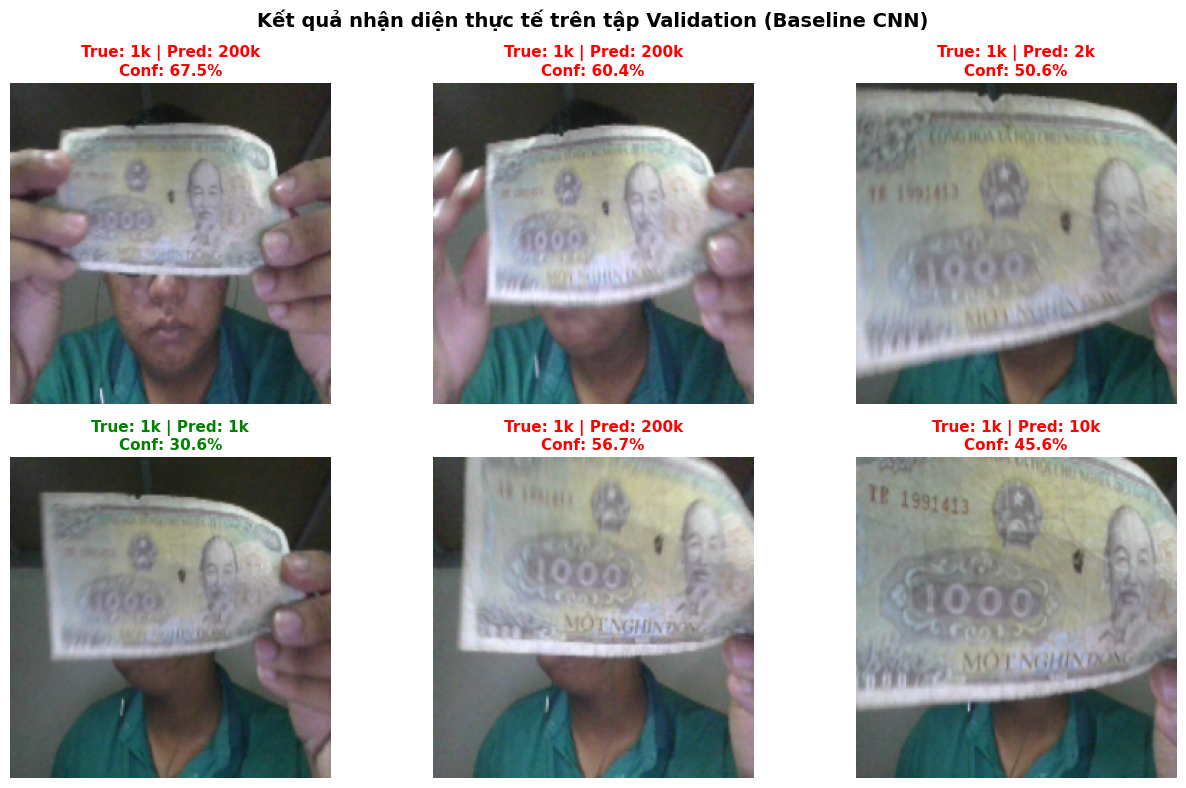

In [5]:
ckpt_path = PROJECT_ROOT / 'artifacts' / 'checkpoints' / 'baseline_cnn_best.pt'
if ckpt_path.exists():
    checkpoint = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    print(f"Đã nạp checkpoint tốt nhất tại epoch {checkpoint['epoch']} với metrics:")
    for k, v in checkpoint['metrics'].items():
        print(f"  - {k}: {v}")

    # Lấy 1 batch từ val_loader
    images, labels = next(iter(val_loader))
    with torch.no_grad():
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        confidences, preds = torch.max(probs, dim=1)

    label_names = ['1k', '2k', '5k', '10k', '20k', '50k', '100k', '200k', '500k']
    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    for i, ax in enumerate(axes.flat):
        img_arr = denormalize_tensor(images[i])
        true_cls = label_names[labels[i].item()]
        pred_cls = label_names[preds[i].item()]
        conf = confidences[i].item() * 100
        is_correct = (preds[i].item() == labels[i].item())

        ax.imshow(img_arr)
        color = 'green' if is_correct else 'red'
        ax.set_title(f"True: {true_cls} | Pred: {pred_cls}\nConf: {conf:.1f}%", fontsize=11, fontweight='bold', color=color)
        ax.axis('off')

    plt.suptitle('Kết quả nhận diện thực tế trên tập Validation (Baseline CNN)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('Checkpoint chưa tồn tại.')